# PI3Kα (4JPS) — Step 9: Top-three docking pose and contact analysis

**Tryptanthrin anticancer capstone** | Reference: 4JPS / 1LT | Input: **`PI3Kalpha_Step8_Docking.zip`** only.

This notebook identifies the three best-ranked compounds **by Vina score**, extracts pose 1, measures atom-level and residue-level distances, flags close polar contacts for follow-up, checks possible severe close contacts, and produces interactive HTML pose views. The original IDs and ML metadata are preserved.

**Interpretation:** A contact distance is not a confirmed hydrogen bond, hydrophobic interaction, or binding mechanism. Docking scores do not establish inhibitory potency. The reference redocking (RMSD 0.6039 Å) only supports pose recovery for the reference ligand with this setup.


## 1. Install and upload Step 8 ZIP

In [1]:
%pip -q install pandas numpy matplotlib py3Dmol
from pathlib import Path
from google.colab import files
from IPython.display import display, HTML
import zipfile, json, io, shutil, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import py3Dmol

print('Upload PI3Kalpha_Step8_Docking.zip:')
uploaded = files.upload()
archives = [k for k in uploaded if k.lower().endswith('.zip')]
if len(archives) != 1:
    raise RuntimeError(f'Upload exactly one Step 8 ZIP; got {archives}')
archive_name=archives[0]
work=Path('PI3Kalpha_Step9_Analysis')
(work/'results').mkdir(parents=True,exist_ok=True)
(work/'analysis').mkdir(exist_ok=True)
(work/'structures').mkdir(exist_ok=True)
with zipfile.ZipFile(archive_name) as z:
    assert z.testzip() is None, 'Corrupt ZIP'
    required=['results/PI3Kalpha_docking_with_ML_context.csv', '4JPS_AB_distance_filtered.pdbqt','PI3Kalpha_step8_docking_report.json']
    for key in required:
        assert key in z.namelist(), f'Missing {key}'
    df=pd.read_csv(io.BytesIO(z.read(required[0])))
    rec_data=z.read(required[1]).decode('utf-8')
    (work/'structures'/'4JPS_AB_distance_filtered.pdbqt').write_text(rec_data)
    report=json.loads(z.read(required[2]))
    (work/'results'/'PI3Kalpha_step8_docking_report.json').write_text(json.dumps(report,indent=2))
    poses={Path(name).stem.replace('_docked',''):z.read(name).decode('utf-8')
           for name in z.namelist() if name.startswith('results/') and name.endswith('_docked.pdbqt')}
assert df['Analog_ID'].is_unique and len(df)==10
assert df['docking_ok'].astype(str).str.lower().eq('true').all(), 'Some docking failures; review Step 8 first'
assert len(poses)==10, f'Expected 10 docked pose files, got {len(poses)}'
print('Verified all 10 docked compounds and prepared receptor.')
print('Step 6 reference RMSD (Å):',report['input_redocking_RMSD_A'])


Upload PI3Kalpha_Step8_Docking.zip:


Saving PI3Kalpha_Step8_Docking.zip to PI3Kalpha_Step8_Docking.zip
Verified all 10 docked compounds and prepared receptor.
Step 6 reference RMSD (Å): 0.6039


## 2. Select top three by docking score (not original ML selection rank)

In [2]:
ranking=df.sort_values('vina_best_affinity_kcal_mol',ascending=True).reset_index(drop=True)
ranking.insert(0,'Docking_rank',np.arange(1,len(ranking)+1))
ranking.to_csv(work/'results'/'PI3Kalpha_ranked_docking_with_ML_context.csv',index=False)
top3=ranking.head(3).copy()
cols=['Docking_rank','Analog_ID','vina_best_affinity_kcal_mol','Consensus_pIC50','Max_train_Tanimoto','QED','SA_score','PAINS_flag','Brenk_flag']
display(top3[cols])
assert set(top3['Analog_ID']).issubset(poses)


,Docking_rank,Analog_ID,vina_best_affinity_kcal_mol,Consensus_pIC50,Max_train_Tanimoto,QED,SA_score,PAINS_flag,Brenk_flag
0,1,TRY_6db5e7a7802259ab,-10.290,6.29428,0.409836,0.540506,2.488290,False,False
1,2,TRY_c88335488290afb4,-10.261,6.25409,0.403226,0.556121,2.444439,False,False
2,3,TRY_c6b27d68ce6ec718,-10.175,6.36582,0.413333,0.560274,2.506605,False,False


## 3. Parse fixed-column PDBQT heavy atoms and extract model 1

In [3]:
def read_atom_lines(text, first_model_only=False):
    lines=[]
    in_model=not first_model_only
    model_seen=False
    for line in text.splitlines():
        if line.startswith('MODEL'):
            if first_model_only and model_seen: break
            model_seen=True; in_model=True; continue
        if line.startswith('ENDMDL') and first_model_only: break
        if not in_model or not line.startswith(('ATOM  ','HETATM')): continue
        atom_type=line.split()[-1].upper()
        if atom_type in ('H','HD','D'): continue
        try:
            xyz=np.array([float(line[30:38]),float(line[38:46]),float(line[46:54])])
            assert np.all(np.isfinite(xyz))
            entry={'atom':line[12:16].strip(),'resname':line[17:20].strip(),
                   'chain':line[21].strip(),'resseq':int(line[22:26]),
                   'xyz':xyz,'atom_type':atom_type,'line':line}
        except (ValueError,AssertionError) as e:
            raise RuntimeError(f'Bad PDBQT atom line: {line}') from e
        lines.append(entry)
    return lines

receptor=read_atom_lines(rec_data)
assert len(receptor)>1000
results=[]; atom_contacts=[]; residue_contacts=[]; ligand_structures={}
for _,row in top3.iterrows():
    ligand_id=row['Analog_ID']
    pose=read_atom_lines(poses[ligand_id],first_model_only=True)
    assert len(pose)>10, f'No model 1 heavy atoms for {ligand_id}'
    ligand_structures[ligand_id]=pose
    (work/'structures'/f'{ligand_id}_model1.pdb').write_text('\n'.join(a['line'][:66] for a in pose)+'\nEND\n')
    lxyz=np.array([a['xyz'] for a in pose]); rxyz=np.array([a['xyz'] for a in receptor]);
    dmat=np.linalg.norm(lxyz[:,None,:]-rxyz[None,:,:],axis=2)
    nearby=np.argwhere(dmat<=4.0)
    close=np.argwhere(dmat<2.0)
    min_dist=float(dmat.min())
    resmin={}
    for i,j in nearby:
        l=pose[i];r=receptor[j];d=float(dmat[i,j]);key=(r['chain'],r['resseq'],r['resname'])
        resmin[key]=min(d,resmin.get(key,float('inf')))
        polar=l['atom_type'] in ('N','NA','OA','O') and r['atom_type'] in ('N','NA','OA','O') and d<=3.5
        atom_contacts.append({'Analog_ID':ligand_id,'ligand_atom':l['atom'],
            'ligand_type':l['atom_type'],'receptor_chain':r['chain'],
            'receptor_residue':r['resname']+str(r['resseq']),
            'receptor_atom':r['atom'],'receptor_type':r['atom_type'],
            'distance_A':round(d,3),'heteroatom_proximity_le_3p5A':bool(polar)})
    for (ch,rn,restype),d in sorted(resmin.items(),key=lambda x:x[1]):
        residue_contacts.append({'Analog_ID':ligand_id,'chain':ch,'residue':restype+str(rn),
                                 'min_distance_A':round(d,3)})
    results.append({'Analog_ID':ligand_id,'vina_best_affinity_kcal_mol':float(row['vina_best_affinity_kcal_mol']),
                    'ligand_heavy_atoms':len(pose),'residues_within_4A':len(resmin),
                    'atom_pairs_within_4A':len(nearby),'atom_pairs_below_2A':len(close),
                    'min_interatomic_distance_A':round(min_dist,3),
                    'preliminary_pose_quality_flag':'REVIEW_CLOSE_CONTACTS' if len(close)>0 else 'NO_LT_2A_CONTACTS'})

atom_df=pd.DataFrame(atom_contacts).sort_values(['Analog_ID','distance_A'])
res_df=pd.DataFrame(residue_contacts).sort_values(['Analog_ID','min_distance_A'])
summary=pd.DataFrame(results)
atom_df.to_csv(work/'analysis'/'PI3Kalpha_top3_atom_contacts.csv',index=False)
res_df.to_csv(work/'analysis'/'PI3Kalpha_top3_residue_contacts.csv',index=False)
summary.to_csv(work/'results'/'PI3Kalpha_top3_pose_quality.csv',index=False)
display(summary)
for ligand_id in top3['Analog_ID']:
    print('\n',ligand_id)
    display(res_df[res_df['Analog_ID']==ligand_id].head(12))


,Analog_ID,vina_best_affinity_kcal_mol,ligand_heavy_atoms,residues_within_4A,atom_pairs_within_4A,atom_pairs_below_2A,min_interatomic_distance_A,preliminary_pose_quality_flag
0,TRY_6db5e7a7802259ab,-10.290,28,15,62,0,3.226,NO_LT_2A_CONTACTS
1,TRY_c88335488290afb4,-10.261,28,13,60,0,2.985,NO_LT_2A_CONTACTS
2,TRY_c6b27d68ce6ec718,-10.175,29,14,59,0,2.745,NO_LT_2A_CONTACTS



 TRY_6db5e7a7802259ab


,Analog_ID,chain,residue,min_distance_A
0,TRY_6db5e7a7802259ab,A,VAL851,3.226
1,TRY_6db5e7a7802259ab,A,TYR836,3.295
2,TRY_6db5e7a7802259ab,A,SER854,3.380
3,TRY_6db5e7a7802259ab,A,TRP780,3.409
4,TRY_6db5e7a7802259ab,A,ASP933,3.474
5,TRY_6db5e7a7802259ab,A,ASN853,3.482
6,TRY_6db5e7a7802259ab,A,ILE848,3.507
7,TRY_6db5e7a7802259ab,A,MET922,3.525
8,TRY_6db5e7a7802259ab,A,ILE932,3.610
9,TRY_6db5e7a7802259ab,A,ASP810,3.709



 TRY_c88335488290afb4


,Analog_ID,chain,residue,min_distance_A
15,TRY_c88335488290afb4,A,TYR836,2.985
16,TRY_c88335488290afb4,A,ASP933,3.217
17,TRY_c88335488290afb4,A,VAL851,3.320
18,TRY_c88335488290afb4,A,SER854,3.377
19,TRY_c88335488290afb4,A,ASP810,3.420
20,TRY_c88335488290afb4,A,TRP780,3.497
21,TRY_c88335488290afb4,A,MET922,3.509
22,TRY_c88335488290afb4,A,ILE848,3.522
23,TRY_c88335488290afb4,A,ASN853,3.556
24,TRY_c88335488290afb4,A,ILE932,3.727



 TRY_c6b27d68ce6ec718


,Analog_ID,chain,residue,min_distance_A
28,TRY_c6b27d68ce6ec718,A,VAL851,2.745
29,TRY_c6b27d68ce6ec718,A,SER854,3.074
30,TRY_c6b27d68ce6ec718,A,MET772,3.337
31,TRY_c6b27d68ce6ec718,A,ILE848,3.364
32,TRY_c6b27d68ce6ec718,A,MET922,3.513
33,TRY_c6b27d68ce6ec718,A,TRP780,3.558
34,TRY_c6b27d68ce6ec718,A,ASP933,3.579
35,TRY_c6b27d68ce6ec718,A,TYR836,3.590
36,TRY_c6b27d68ce6ec718,A,ILE932,3.591
37,TRY_c6b27d68ce6ec718,A,GLU849,3.636


## 4. Visualise top-three ligand poses with nearby receptor residues

In [4]:
for ligand_id in top3['Analog_ID']:
    atoms=ligand_structures[ligand_id]
    xyz=np.array([a['xyz'] for a in atoms])
    near=[a for a in receptor if np.linalg.norm(xyz-np.asarray(a['xyz']),axis=1).min()<=6.0]
    local_pdb='\n'.join(a['line'][:66] for a in near)+'\nEND\n'
    ligand_pdb='\n'.join(a['line'][:66] for a in atoms)+'\nEND\n'
    view=py3Dmol.view(width=720,height=420)
    view.addModel(local_pdb,'pdb')
    view.setStyle({'model':0},{'stick':{'radius':0.12,'colorscheme':'greenCarbon'}})
    view.addModel(ligand_pdb,'pdb')
    view.setStyle({'model':1},{'stick':{'radius':0.25,'colorscheme':'cyanCarbon'}})
    view.zoomTo({'model':1})
    html=view._make_html()
    (work/'analysis'/f'{ligand_id}_pose_view.html').write_text(html,encoding='utf-8')
    print('Pose view:',ligand_id,'(cyan = docked analog; green = nearby receptor)')
    display(HTML(html))
print('Note: these are coordinate visualisations; interpret chemical interactions separately.')


Pose view: TRY_6db5e7a7802259ab (cyan = docked analog; green = nearby receptor)


Pose view: TRY_c88335488290afb4 (cyan = docked analog; green = nearby receptor)


Pose view: TRY_c6b27d68ce6ec718 (cyan = docked analog; green = nearby receptor)


Note: these are coordinate visualisations; interpret chemical interactions separately.


## 5. Summary figure and final ZIP

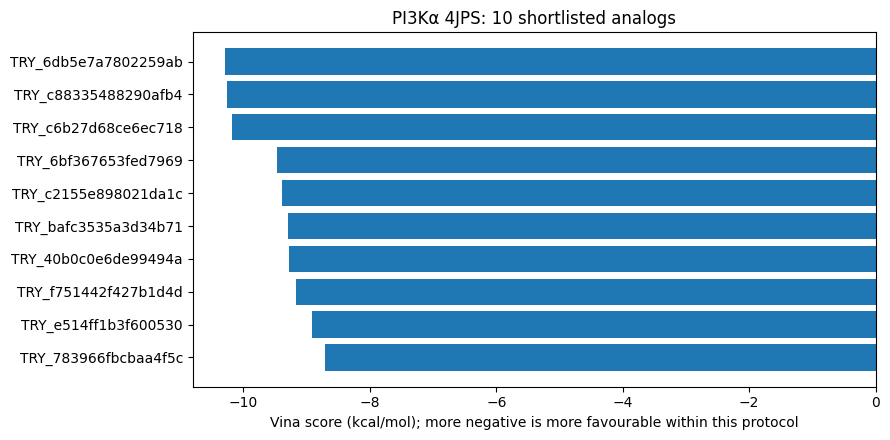

Downloaded package: /content/PI3Kalpha_Step9_Interaction_Analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
fig, ax=plt.subplots(figsize=(9,4.5))
ax.barh(ranking['Analog_ID'],ranking['vina_best_affinity_kcal_mol'])
ax.invert_yaxis()
ax.set_xlabel('Vina score (kcal/mol); more negative is more favourable within this protocol')
ax.set_title('PI3Kα 4JPS: 10 shortlisted analogs')
fig.tight_layout()
fig.savefig(work/'results'/'PI3Kalpha_docking_score_ranking.png',dpi=170,bbox_inches='tight')
plt.show()
notes={
 'target':'PI3Kalpha','receptor':'4JPS','reference_ligand':'1LT (alpelisib)',
 'source_step8_redocking_rmsd_A':report['input_redocking_RMSD_A'],
 'top3_by_vina_score':top3['Analog_ID'].tolist(),
 'nearby_residue_cutoff_A':4.0,'polar_heteroatom_proximity_cutoff_A':3.5,
 'strong_clash_screen_A':2.0,
 'limitations':['Distances do not establish hydrogen bonding, hydrophobic interactions or inhibitory activity',
                'Raw Vina scores are computational estimates; do not compare scores directly between different targets',
                'Ten distant receptor residues were excluded during preparation',
                'ADMET/SA and ML applicability need consideration in final candidate selection'],
 'next':'Review top-three chemical contacts and poses; integrate with ML/ADMET; write final report'
}
(work/'analysis'/'PI3Kalpha_step9_analysis_report.json').write_text(json.dumps(notes,indent=2))
zipname=shutil.make_archive('PI3Kalpha_Step9_Interaction_Analysis','zip',work)
print('Downloaded package:',zipname)
files.download(zipname)
